In [27]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.feature_selection import mutual_info_regression

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [28]:
df = pd.read_csv("train.csv")
df.head()

,claim_id,claim_amount,driver_age,previous_claim_count,vehicle_value,damage_severity,incident_type,repair_shop_id,phone_hash,address_id,is_fraud
0,C000001,254.29,42.0,2,11900.0,low,collision,Sb7a282e399,Pfd09f60f9e,A48656b5517,0
1,C000002,592.05,29.0,0,14600.0,low,collision,S9399315447,P8a7ff077bb,A53e94c25e5,0
2,C000007,980.14,58.0,0,17550.0,low,glass,S1bb582e486,P02246ac9cc,A84ed465d68,0
3,C000008,729.04,44.0,0,18550.0,low,collision,S7e56cdce9e,P8e162b8d1a,A46a2d8b11d,0
4,C000009,16145.05,34.0,0,29300.0,NaN,theft,S1bb582e486,Pd299199a4f,Ac638621b9b,0


Mutual info and data shape


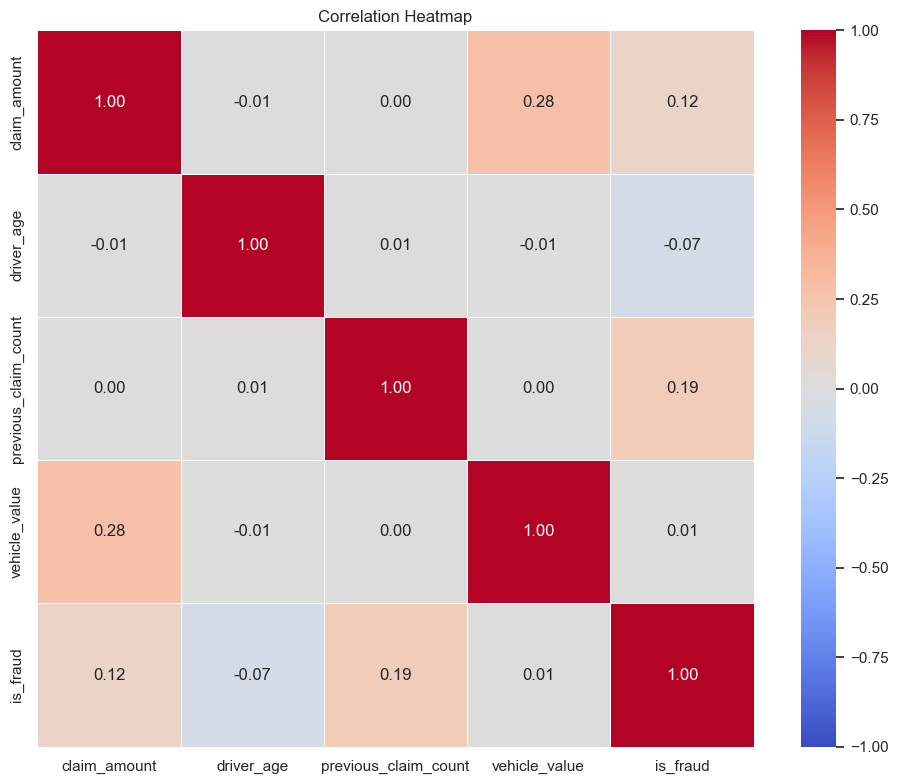

In [29]:
# Correlation matrix (numeric columns only)
corr = df.corr(numeric_only=True)

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,        # show the numbers
    fmt=".2f",         # 2 decimal places
    cmap="coolwarm",   # blue = negative, red = positive
    vmin=-1, vmax=1,   # fixed scale
    center=0,
    square=True,
    linewidths=0.5,
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

previous_claim_count    0.017435
claim_amount            0.006998
vehicle_value           0.003619
driver_age              0.002538
dtype: float64


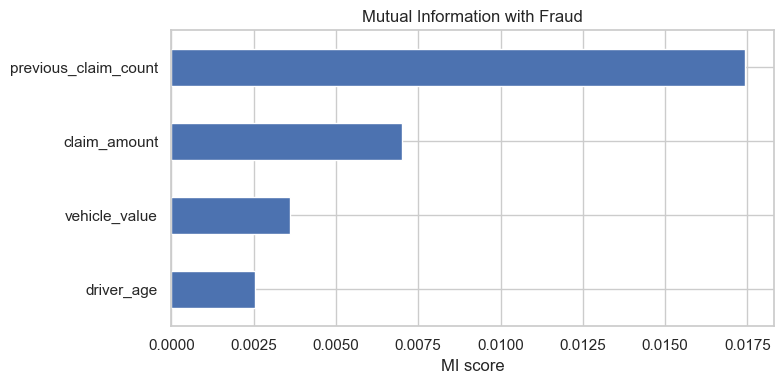

In [30]:
# Mutual Information
from sklearn.feature_selection import mutual_info_classif
features = ["claim_amount", "driver_age", "previous_claim_count", "vehicle_value", ]
target = "is_fraud"

df_2 = df[features + [target]].dropna()
df_2[target] = df[target].replace({"Yes": 1, "No": 0, "Y": 1, "N": 0, True: 1, False: 0}).astype(int)

X = df_2[features]
y = df_2[target]

mi = mutual_info_classif(X, y, random_state=42)
mi_scores = pd.Series(mi, index=features).sort_values(ascending=False)

print(mi_scores)

mi_scores.sort_values().plot(kind="barh", figsize=(8, 4), title="Mutual Information with Fraud")
plt.xlabel("MI score")
plt.tight_layout()
plt.show()

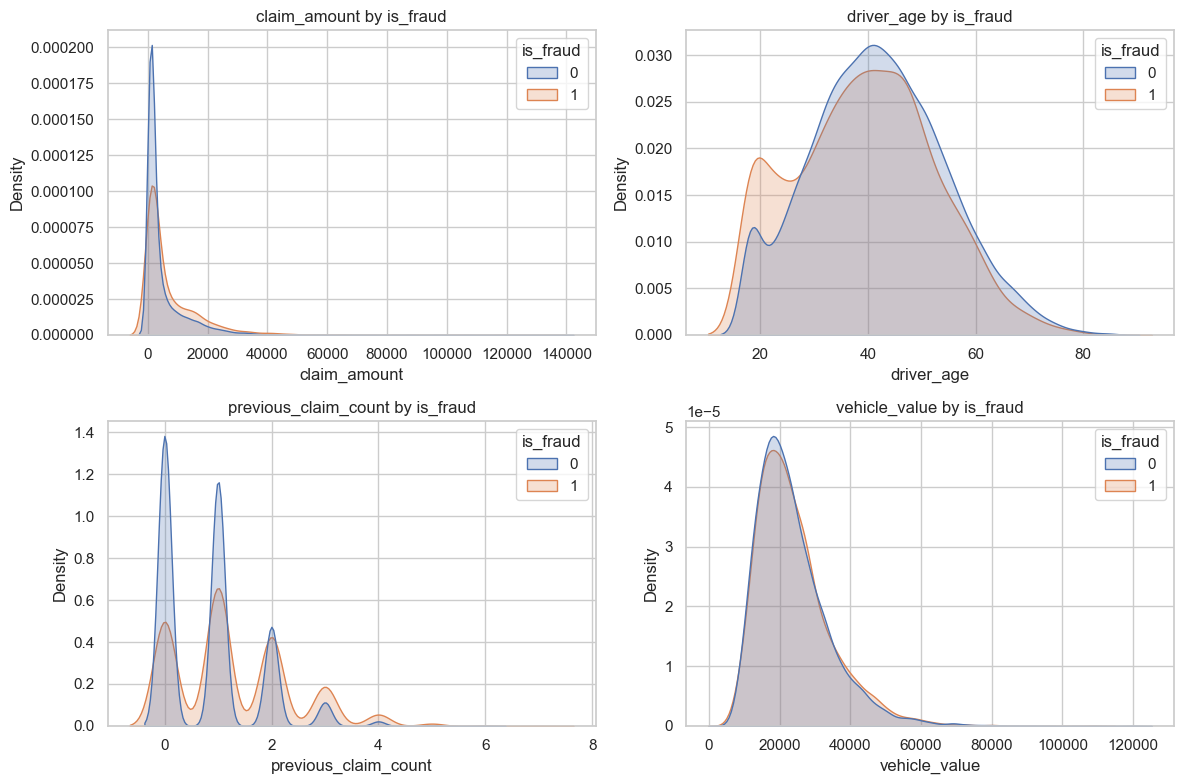

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target = "is_fraud"
numeric = ["claim_amount", "driver_age", "previous_claim_count", "vehicle_value"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), numeric):
    sns.kdeplot(data=df, x=col, hue=target, common_norm=False, fill=True, ax=ax)
    ax.set_title(f"{col} by {target}")
plt.tight_layout()
plt.show()

## MORE THEY CLAIM MORE THEY FRAUD?

In [32]:
vc = df["address_id"].value_counts()

print("unique addresses:", len(vc))
print("duplicated addresses:", (vc > 1).sum())
print("rows on a duplicated address:", df["address_id"].isin(vc[vc > 1].index).sum())

# Distribution of claims per address
print(vc.value_counts().sort_index())

unique addresses: 9160
duplicated addresses: 5638
rows on a duplicated address: 16478
count
1     3522
2     2842
3     1660
4      648
5      263
6       67
7       45
8       38
9       19
10      17
11      12
12       8
13       3
14       4
15       1
16       2
17       3
19       2
20       1
21       1
22       1
23       1
Name: count, dtype: int64


## PHONE VS FRAUD

In [ ]:
print("rows:", len(df))
print("unique phones:", len(vc))
print("phones used once:", (vc == 1).sum())
print("duplicated phones (2+ claims):", (vc > 1).sum())
print("extra rows (repeat of an earlier phone):", df["phone_hash"].duplicated().sum())
print("most claims on one phone:", vc.max(), " | median:", vc.median())


rows: 20000
unique phones: 9160
phones used once: 3522
duplicated phones (2+ claims): 5638
rows on a duplicated phone: 0
extra rows (repeat of an earlier phone): 10155
most claims on one phone: 23  | median: 2.0


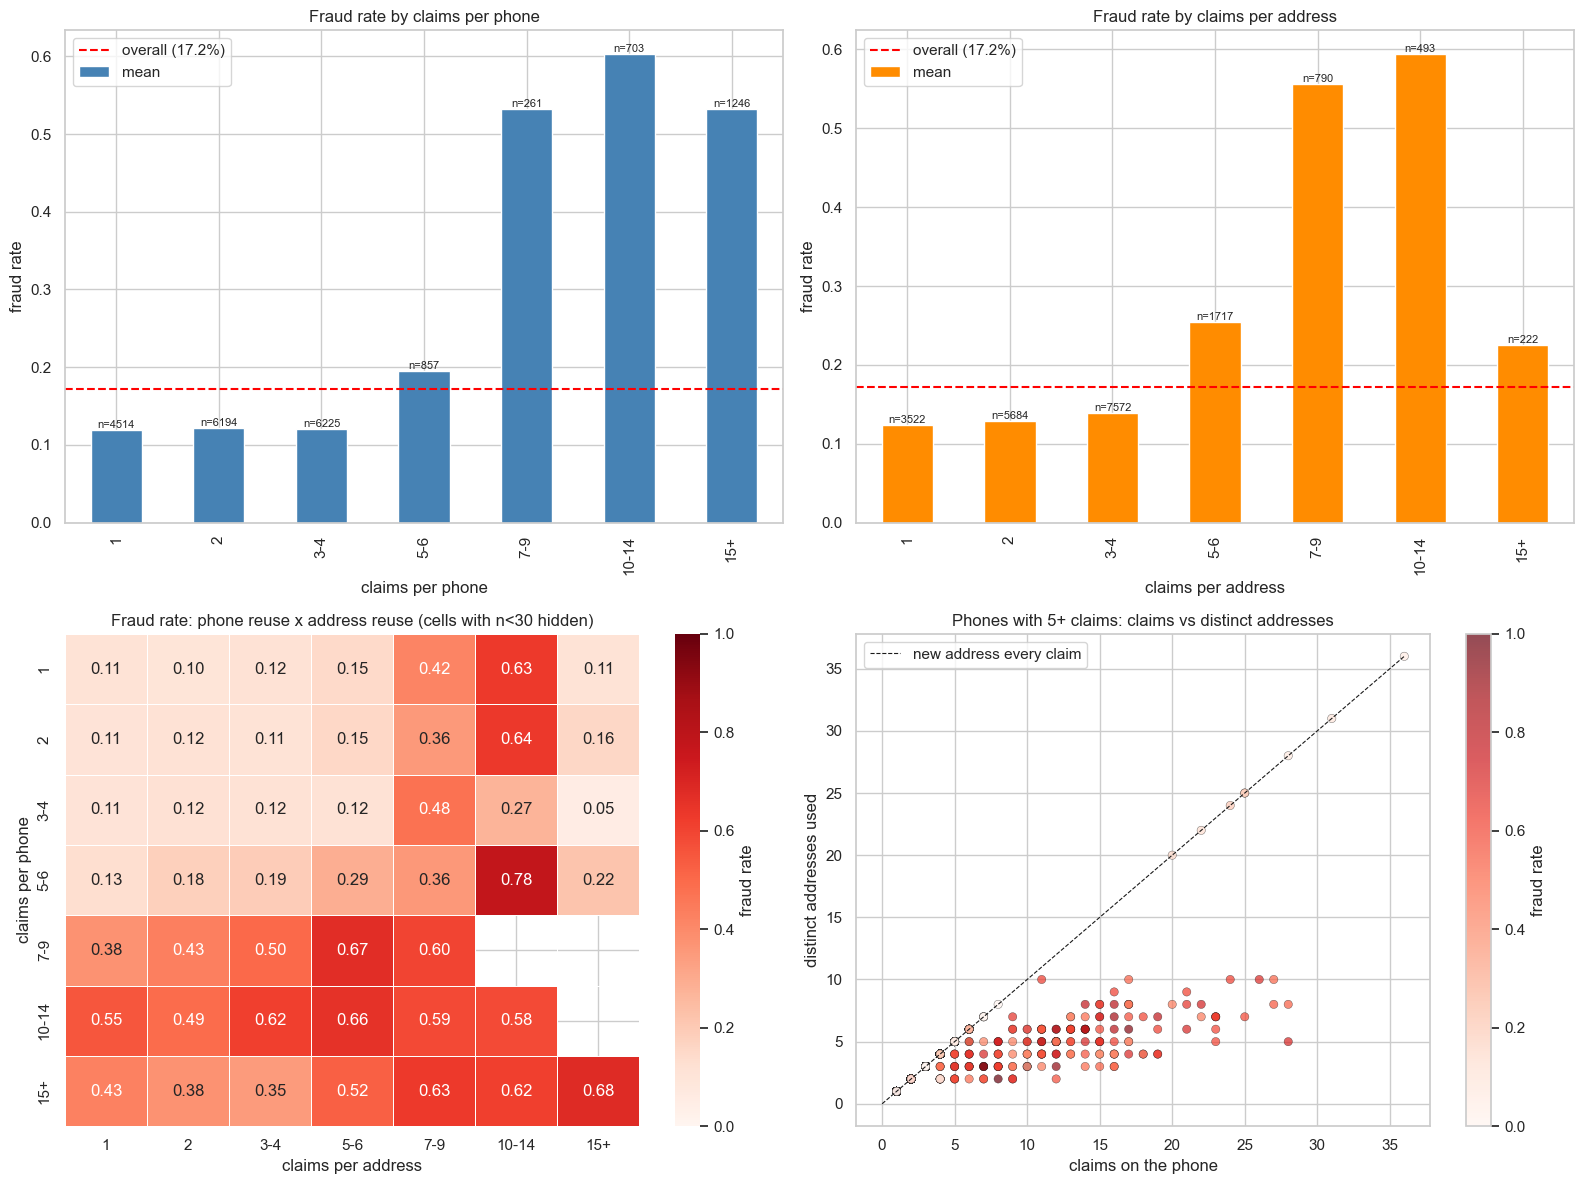

             mean  count
addr_ratio              
(0.0, 0.5]  0.605    134
(0.5, 0.9]  0.582     37
(0.9, 1.0]  0.120   9674


In [36]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

target = "is_fraud"
base = df[target].mean()

# --- Features: how often each phone / address is reused ---
df["phone_n"] = df.groupby("phone_hash")["claim_id"].transform("count")
df["addr_n"] = df.groupby("address_id")["claim_id"].transform("count")

bins = [0, 1, 2, 4, 6, 9, 14, 100]
labels = ["1", "2", "3-4", "5-6", "7-9", "10-14", "15+"]
df["phone_bucket"] = pd.cut(df["phone_n"], bins=bins, labels=labels)
df["addr_bucket"] = pd.cut(df["addr_n"], bins=bins, labels=labels)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Phone reuse vs fraud
p = df.groupby("phone_bucket", observed=True)[target].agg(["mean", "count"])
p["mean"].plot(kind="bar", ax=axes[0, 0], color="steelblue")
axes[0, 0].axhline(base, color="red", linestyle="--", label=f"overall ({base:.1%})")
axes[0, 0].set_title("Fraud rate by claims per phone")
axes[0, 0].set_xlabel("claims per phone")
axes[0, 0].set_ylabel("fraud rate")
axes[0, 0].legend()
for i, (m, c) in enumerate(zip(p["mean"], p["count"])):
    axes[0, 0].text(i, m, f"n={c}", ha="center", va="bottom", fontsize=8)

# 2. Address reuse vs fraud
a = df.groupby("addr_bucket", observed=True)[target].agg(["mean", "count"])
a["mean"].plot(kind="bar", ax=axes[0, 1], color="darkorange")
axes[0, 1].axhline(base, color="red", linestyle="--", label=f"overall ({base:.1%})")
axes[0, 1].set_title("Fraud rate by claims per address")
axes[0, 1].set_xlabel("claims per address")
axes[0, 1].set_ylabel("fraud rate")
axes[0, 1].legend()
for i, (m, c) in enumerate(zip(a["mean"], a["count"])):
    axes[0, 1].text(i, m, f"n={c}", ha="center", va="bottom", fontsize=8)

# 3. Phone x Address: fraud rate when both are reused
grid = df.pivot_table(index="phone_bucket", columns="addr_bucket",
                      values=target, aggfunc="mean", observed=True)
counts = df.pivot_table(index="phone_bucket", columns="addr_bucket",
                        values=target, aggfunc="count", observed=True)

sns.heatmap(grid, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1,
            linewidths=0.5, ax=axes[1, 0], cbar_kws={"label": "fraud rate"})
axes[1, 0].set_title("Fraud rate: phone reuse x address reuse (cells with n<30 hidden)")
axes[1, 0].set_xlabel("claims per address")
axes[1, 0].set_ylabel("claims per phone")

# 4. Phone-address link: how many different addresses does each phone touch?
ph = (df.groupby("phone_hash")
        .agg(claims=("claim_id", "count"),
             distinct_addr=("address_id", "nunique"),
             fraud_rate=(target, "mean")))

sc = axes[1, 1].scatter(ph["claims"], ph["distinct_addr"], c=ph["fraud_rate"],
                        cmap="Reds", vmin=0, vmax=1, alpha=0.7, edgecolor="k", linewidth=0.3)
lim = ph["claims"].max()
axes[1, 1].plot([0, lim], [0, lim], "k--", linewidth=0.8, label="new address every claim")
axes[1, 1].set_title("Phones with 5+ claims: claims vs distinct addresses")
axes[1, 1].set_xlabel("claims on the phone")
axes[1, 1].set_ylabel("distinct addresses used")
axes[1, 1].legend()
plt.colorbar(sc, ax=axes[1, 1], label="fraud rate")

plt.tight_layout()
plt.show()

# Quick numeric summary of the phone-address relationship
ph["addr_ratio"] = ph["distinct_addr"] / ph["claims"]
print(ph.groupby(pd.cut(ph["addr_ratio"], [0, 0.5, 0.9, 1.0]), observed=True)["fraud_rate"]
        .agg(["mean", "count"]).round(3))

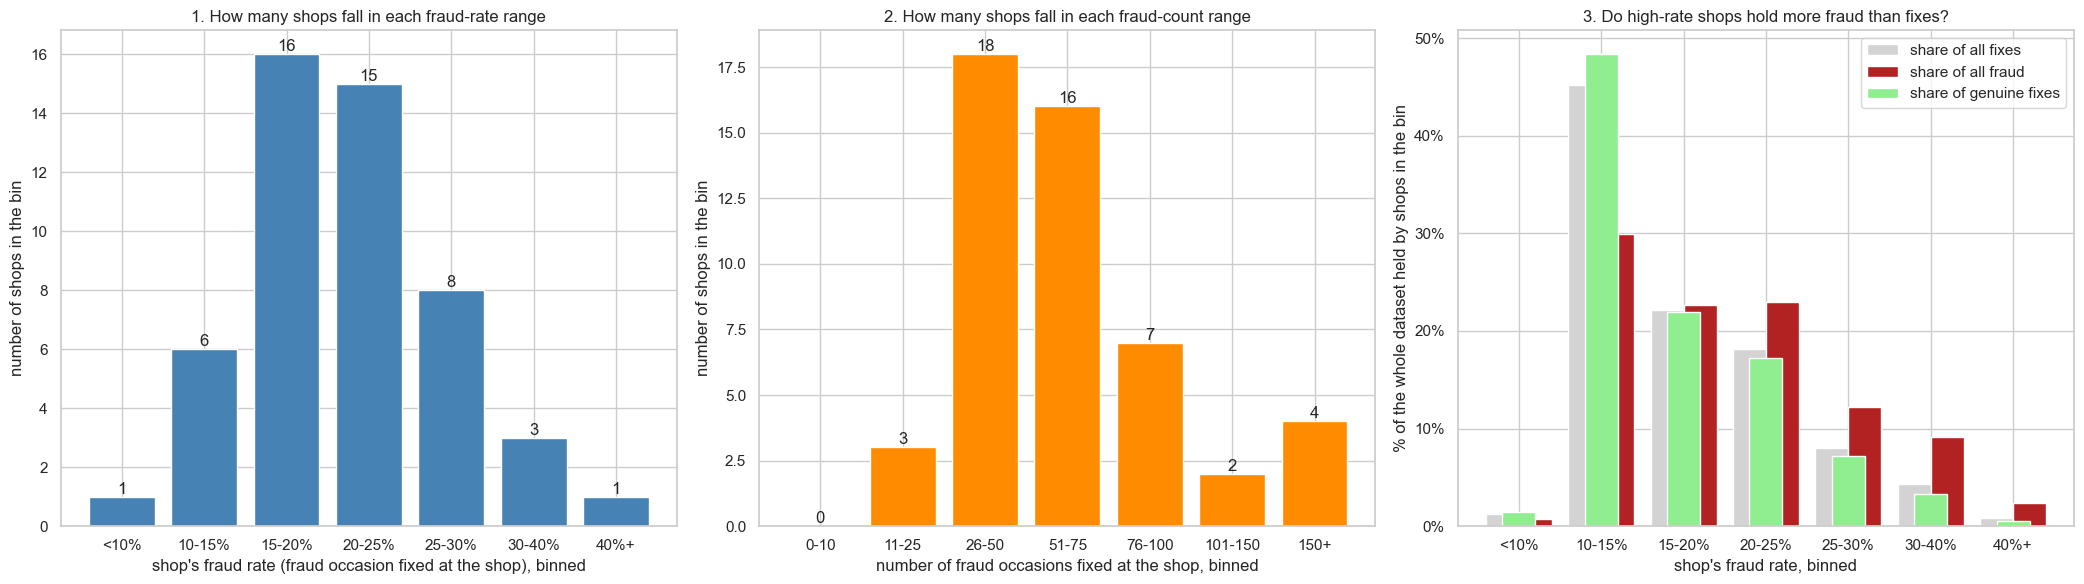

          shops  claims  fraud  share_of_fix  share_of_fraud  genuine  \
rate_bin                                                                
<10%          1     259     25         0.013           0.007      234   
10-15%        6    9041   1027         0.452           0.299     8014   
15-20%       16    4420    778         0.221           0.227     3642   
20-25%       15    3638    788         0.182           0.229     2850   
25-30%        8    1611    421         0.081           0.123     1190   
30-40%        3     860    313         0.043           0.091      547   
40%+          1     171     82         0.009           0.024       89   

          share_of_genuine  
rate_bin                    
<10%                 0.014  
10-15%               0.484  
15-20%               0.220  
20-25%               0.172  
25-30%               0.072  
30-40%               0.033  
40%+                 0.005  

Overall fraud rate: 17.2%


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

target = "is_fraud"
base = df[target].mean()
total_fraud = df[target].sum()

shop = (df.groupby("repair_shop_id")
          .agg(claims=("claim_id", "count"),
               fraud=(target, "sum"),
               fraud_rate=(target, "mean")))

# ---------- Bins ----------
rate_bins = [0, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 1.0]
rate_labels = ["<10%", "10-15%", "15-20%", "20-25%", "25-30%", "30-40%", "40%+"]
shop["rate_bin"] = pd.cut(shop["fraud_rate"], bins=rate_bins, labels=rate_labels, include_lowest=True)

count_bins = [0, 10, 25, 50, 75, 100, 150, 1000]
count_labels = ["0-10", "11-25", "26-50", "51-75", "76-100", "101-150", "150+"]
shop["count_bin"] = pd.cut(shop["fraud"], bins=count_bins, labels=count_labels, include_lowest=True)

# Per-bin summary: how many shops, and how much of the claims / fraud they fix
by_rate = (shop.groupby("rate_bin", observed=False)
               .agg(shops=("claims", "size"), claims=("claims", "sum"), fraud=("fraud", "sum")))
by_rate["share_of_fix"] = by_rate["claims"] / len(df)
by_rate["share_of_fraud"] = by_rate["fraud"] / total_fraud
by_rate["genuine"] = by_rate["claims"] - by_rate["fraud"]
by_rate["share_of_genuine"] = by_rate["genuine"] / (len(df) - total_fraud)

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# 1. Number of shops per fraud-RATE bin
ax = axes[0]
counts = shop["rate_bin"].value_counts().reindex(rate_labels)
ax.bar(rate_labels, counts.values, color="steelblue")
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
ax.set_xlabel("shop's fraud rate (fraud occasion fixed at the shop), binned")
ax.set_ylabel("number of shops in the bin")
ax.set_title("1. How many shops fall in each fraud-rate range")

# 2. Number of shops per fraud-COUNT bin
ax = axes[1]
counts2 = shop["count_bin"].value_counts().reindex(count_labels)
ax.bar(count_labels, counts2.values, color="darkorange")
for i, v in enumerate(counts2.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
ax.set_xlabel("number of fraud occasions fixed at the shop, binned")
ax.set_ylabel("number of shops in the bin")
ax.set_title("2. How many shops fall in each fraud-count range")

# 3. Share of fixes vs share of fraud in each fraud-rate bin
ax = axes[2]
x = np.arange(len(rate_labels))
ax.bar(x - 0.2, by_rate["share_of_fix"].values, 0.4, label="share of all fixes", color="lightgray")
ax.bar(x + 0.2, by_rate["share_of_fraud"].values, 0.4, label="share of all fraud", color="firebrick")
ax.bar(x, by_rate["share_of_genuine"].values, 0.4, label="share of genuine fixes", color="lightgreen")

ax.set_xticks(x)
ax.set_xticklabels(rate_labels)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("shop's fraud rate, binned")
ax.set_ylabel("% of the whole dataset held by shops in the bin")
ax.set_title("3. Do high-rate shops hold more fraud than fixes?")
ax.legend()

plt.tight_layout()
plt.show()

print(by_rate.round(3))
print(f"\nOverall fraud rate: {base:.1%}")